# Data processing
## Step 1: Data Loading and basic check

In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("bank-additional-full.csv", sep=";")

In [2]:
print(df.head())
print(df.shape)

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

From this info, there are no null values. However, there exists "unknown" category.
Then check Categorical Values.

In [4]:
for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts())


 job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

 marital
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

 education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

 default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

 housing
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

 loan
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

 contact
con

In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [6]:
#Only 12 duplicate rows, delete them.
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (41176, 21)


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


## Step 2: Analysis based on checked info

In [8]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     36537
yes     4639
Name: count, dtype: int64
y
no     0.887337
yes    0.112663
Name: proportion, dtype: float64


In [9]:
target_distribution = (
    df["y"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_distribution)

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [10]:
df["y"] = df["y"].map({
    "no": 0,
    "yes": 1
})

print(df["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


0 = no subscription
1 = subscribed

In [11]:
'''
# 999 means never contacted before. So separate it into an individual column
# False = 0 True = 1
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays_clean"] = df["pdays"].replace(999, np.nan)
# pdays is separated into previously_contacted and pdays_clean
df = df.drop(columns=["pdays"])
print(df[["previously_contacted", "pdays_clean"]].head(20))
print(df["previously_contacted"].value_counts())
print(df["pdays_clean"].describe())
'''
# After checking the outcome, less than 10% of customers were previously contacted

'\n# 999 means never contacted before. So separate it into an individual column\n# False = 0 True = 1\ndf["previously_contacted"] = (df["pdays"] != 999).astype(int)\ndf["pdays_clean"] = df["pdays"].replace(999, np.nan)\n# pdays is separated into previously_contacted and pdays_clean\ndf = df.drop(columns=["pdays"])\nprint(df[["previously_contacted", "pdays_clean"]].head(20))\nprint(df["previously_contacted"].value_counts())\nprint(df["pdays_clean"].describe())\n'

In [12]:
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

df["pdays_clean"] = np.where(
    df["pdays"] == 999,
    0,
    df["pdays"]
)

df = df.drop(columns=["pdays"])

In [13]:
#df_with_duration = df.copy()
#df_without_duration = df.drop(columns=["duration"]).copy()

Almost done, check again.

In [14]:
print("Final shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

print("\nData types:")
print(df.dtypes)

Final shape: (41176, 22)

Missing values:
age                     0
job                     0
marital                 0
education               0
default                 0
housing                 0
loan                    0
contact                 0
month                   0
day_of_week             0
duration                0
campaign                0
previous                0
poutcome                0
emp.var.rate            0
cons.price.idx          0
cons.conf.idx           0
euribor3m               0
nr.employed             0
y                       0
previously_contacted    0
pdays_clean             0
dtype: int64

Duplicate rows:
0

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64
y
0    0.887337
1    0.112663
Name: proportion, dtype: float64

Data types:
age                       int64
job                      object
marital                  object
education                object
default                  object
housing                  object
loan          

## Setup 

In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42          # one seed for every random step: split, CV folds, models
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)

## Encode categorical features (one-hot)

In [18]:
TARGET = "y"
CATEGORICAL_COLS = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome"]
NUMERIC_COLS = ["age", "duration", "campaign", "pdays_clean", "previous",
                "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
BINARY_COLS = ["previously_contacted"]          # already 0/1, no encoding or scaling needed

# every cleaned column must belong to exactly one group
assert set(CATEGORICAL_COLS + NUMERIC_COLS + BINARY_COLS + [TARGET]) == set(df.columns)

df_model = pd.get_dummies(df, columns=CATEGORICAL_COLS, drop_first=True, dtype=int)
print("Shape after one-hot encoding:", df_model.shape)
df_model.head()

Shape after one-hot encoding: (41176, 55)


,age,duration,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,pdays_clean,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,marital_unknown,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes,contact_telephone,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
1,57,149,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
2,37,226,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
3,40,151,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
4,56,307,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0


## Train / test split

In [19]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "  Test:", X_test.shape)
print(f"Subscription rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

Train: (32940, 54)   Test: (8236, 54)
Subscription rate  train: 0.1127   test: 0.1127


## Feature sets with / without duration

In [20]:
featurewithduration = list(X_train.columns)
featurenoduration = [c for c in featurewithduration if c != "duration"]

print(len(featurewithduration), "features with duration |", len(featurenoduration), "features without duration")


54 features with duration | 53 features without duration


## Feature scaling

In [21]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])   # fit on TRAIN only
X_test_scaled[NUMERIC_COLS] = scaler.transform(X_test[NUMERIC_COLS])         # reuse the training mean / std

X_train_scaled[NUMERIC_COLS].describe().loc[["mean", "std"]].round(3)

,age,duration,campaign,pdays_clean,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
mean,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5-fold cross-validation

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
REFIT_METRIC = "f1"

# Model Training

Save model functions

In [47]:
from pathlib import Path
import os
import joblib
import sklearn

# Create the root directory for model caches
MODEL_DIR = Path("model_cache").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Preserve existing in-memory models; create an empty dictionary if absent
grids = globals().get("grids", {})


# Register input types and feature lists for all models
# SVM performs scaling inside its Pipeline, so it uses raw inputs
MODEL_INPUTS = {
    "LR (no duration)": ("scaled", featurenoduration),
    "LR (with duration)": ("scaled", featurewithduration),

    "DT (no duration)": ("raw", featurenoduration),
    "DT (with duration)": ("raw", featurewithduration),

    "SVM (no duration)": ("raw", featurenoduration),
    "SVM (with duration)": ("raw", featurewithduration),

    "RF (no duration)": ("raw", featurenoduration),
    "RF (with duration)": ("raw", featurewithduration),

    "GB (no duration)": ("raw", featurenoduration),
    "GB (with duration)": ("raw", featurewithduration),
}

# Generate an experiment identifier from data, preprocessing, and version
CONTEXT_ID = joblib.hash({
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "scaler": scaler,
    "numeric_cols": NUMERIC_COLS,
    "model_inputs": MODEL_INPUTS,
    "sklearn_version": sklearn.__version__,
})

# Create the output directory for this experiment
RUN_DIR = MODEL_DIR / CONTEXT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)



In [48]:

def atomic_dump(obj, path):
   # Write a temporary file before replacing the target.
    path = Path(path)
    temp = path.with_suffix(path.suffix + ".tmp")

    joblib.dump(obj, temp, compress=3)
    os.replace(temp, path)

# Save evaluation context, including input specifications for all models
atomic_dump({
    "sklearn_version": sklearn.__version__,
    "scaler": scaler,
    "numeric_cols": NUMERIC_COLS,
    "model_inputs": MODEL_INPUTS,
    "X_test": X_test,
    "X_test_scaled": X_test_scaled,
    "y_test": y_test,
}, RUN_DIR / "evaluation_context.joblib")


def cache_path(
    name,
    estimator,
    param_grid,
    X_tr,
    scoring=SCORING,
    refit=REFIT_METRIC,
    cv_spec=cv,
):


    # Generate a cache identifier from the model, training data, and search settings
    signature = joblib.hash({
        "name": name,
        "estimator": estimator,
        "param_grid": param_grid,
        "X_train": X_tr,
        "y_train": y_train,
        "scoring": scoring,
        "refit": refit,
        "cv": cv_spec,
    })

    return RUN_DIR / f"search_{signature}.joblib"


def save_grid(name, grid, X_tr):
    # Save a fitted GridSearchCV object.
    # Determine the save path using the actual search configuration
    path = cache_path(
        name,
        grid.estimator,
        grid.param_grid,
        X_tr,
        scoring=grid.scoring,
        refit=grid.refit,
        cv_spec=grid.cv,
    )

    # Save the best model, best parameters, and complete CV results
    atomic_dump({
        "name": name,
        "grid": grid,
    }, path)

    return path


print("Cache setup completed.")
print("Registered models:", len(MODEL_INPUTS))
print("Results directory:", RUN_DIR)

Cache setup completed.
Registered models: 10
Results directory: D:\Software\JupyterNotebooks\NTU\KM6312_GroupProject\bank-additional\LT\model_cache\02fd97b872b9d2d4b7384550c3b87592


In [25]:

def fit_model(name, estimator, param_grid, X_tr, *,
              force_retrain=False, n_jobs=2):
    path = cache_path(name, estimator, param_grid, X_tr)

    if path.exists() and not force_retrain:
        grid = joblib.load(path)["grid"]
        print(f"[Loaded] {name}")
    else:
        grid = GridSearchCV(
            estimator,
            param_grid,
            cv=cv,
            scoring=SCORING,
            refit=REFIT_METRIC,
            n_jobs=n_jobs,
            verbose=2,        
            pre_dispatch=n_jobs,
            error_score="raise",
        )
        grid.fit(X_tr, y_train)

        save_grid(name, grid, X_tr)
        print(f"[Trained & saved] {name}")

    grids[name] = grid

    i = grid.best_index_
    metric = grid.refit
    print("Best parameters:", grid.best_params_)
    print(
        f"CV {metric}: "
        f"{grid.cv_results_[f'mean_test_{metric}'][i]:.4f} ± "
        f"{grid.cv_results_[f'std_test_{metric}'][i]:.4f}"
    )

    return grid.best_estimator_

## LR + DT (Huang Zhechun)

reuse functions

In [26]:
#grids = {}        # model name -> fitted GridSearchCV (refitted best model in .best_estimator_)
'''
def fit_model(name, estimator, param_grid, X_tr):
    """5-fold CV grid search on the TRAINING set; the best setting (by REFIT_METRIC) is refitted on all of X_tr."""
    grid = GridSearchCV(estimator, param_grid, cv=cv, scoring=SCORING, refit=REFIT_METRIC, n_jobs=-1)
    grid.fit(X_tr, y_train)
    grids[name] = grid
    i = grid.best_index_
    print(f"{name}  |  {X_tr.shape[1]} features  |  {len(grid.cv_results_['params'])} settings x 5 folds")
    print(f"Selected hyperparameters (best mean 5-fold CV {REFIT_METRIC}): {grid.best_params_}")
    print(f"Mean CV {REFIT_METRIC} of the selected setting: "
          f"{grid.cv_results_[f'mean_test_{REFIT_METRIC}'][i]:.4f} ± {grid.cv_results_[f'std_test_{REFIT_METRIC}'][i]:.4f}")
    return grid.best_estimator_
'''

def plot_lr_coefficients(name, k=10):
    """The k largest coefficients of a fitted LR model (continuous features are standardised, so they are comparable)."""
    model = grids[name].best_estimator_
    coefs = pd.Series(model.coef_[0], index=model.feature_names_in_)
    top = coefs.reindex(coefs.abs().nlargest(k).index)[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.barh(top.index, top.values, color=["#2a78d6" if v > 0 else "#e34948" for v in top.values])
    ax.axvline(0, linewidth=0.8)
    ax.set_title(f"{name}: {k} largest coefficients\nblue = raises the odds of 'yes', red = lowers them",
                 fontsize=11, loc="left")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn import metrics

lr_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}


### Model 1: Logistic Regression without duration

[Loaded] LR (no duration)
Best parameters: {'C': 10}
CV f1: 0.3457 ± 0.0063


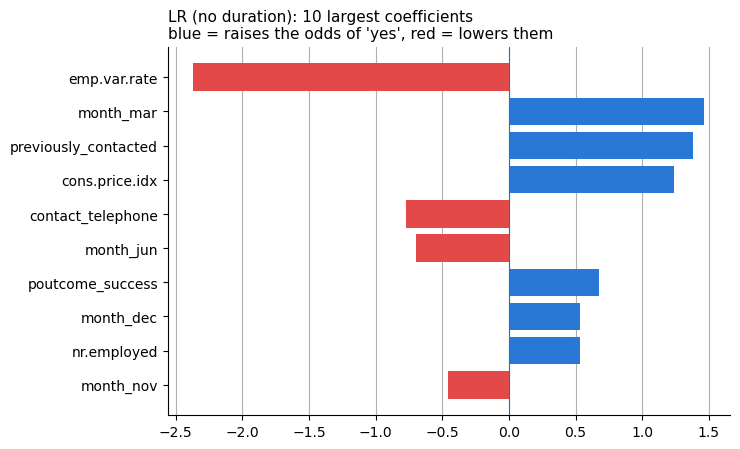

In [28]:
lr_no_duration = fit_model("LR (no duration)",
                           LogisticRegression(solver="lbfgs", max_iter=1000),
                           lr_grid,
                           X_train_scaled[featurenoduration])
plot_lr_coefficients("LR (no duration)")

In [29]:
X_train[["emp.var.rate", "cons.price.idx", "euribor3m", "nr.employed"]].corr().round(2)

,emp.var.rate,cons.price.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.77,0.97,0.91
cons.price.idx,0.77,1.00,0.69,0.52
euribor3m,0.97,0.69,1.00,0.94
nr.employed,0.91,0.52,0.94,1.00


In [30]:
# Impurity of the root node (= the whole training set), computed with the two formulas above
p = y_train.value_counts(normalize=True).sort_index().values          # [p_no, p_yes]
gini_root = 1 - np.sum(p ** 2)
entropy_root = -np.sum(p * np.log2(p))
print(f"Class proportions in the training set: no = {p[0]:.4f}, yes = {p[1]:.4f}")
print(f"Root Gini impurity  G = 1 - sum(p_i^2)        = {gini_root:.4f}   (maximum 0.5 for two classes)")
print(f"Root entropy        H = -sum(p_i * log2(p_i)) = {entropy_root:.4f}   (maximum 1 for two classes)")

Class proportions in the training set: no = 0.8873, yes = 0.1127
Root Gini impurity  G = 1 - sum(p_i^2)        = 0.1999   (maximum 0.5 for two classes)
Root entropy        H = -sum(p_i * log2(p_i)) = 0.5079   (maximum 1 for two classes)


DT setting & functions

In [31]:
# (a) cost-complexity pruning path: alpha = 0 is the unpruned (full) tree
CCP_ALPHAS = [0.0, 1e-5, 3e-5, 1e-4, 2e-4, 3e-4, 5e-4, 1e-3, 2e-3, 5e-3]

# (b) joint grid over the key parameters (2 x 5 x 3 x 3 x 4 = 360 settings x 5 folds; ~2-3 min per model)
DT_GRID = {"criterion": ["gini", "entropy"],
           "max_depth": [5, 7, 10, 15, None],
           "min_samples_split": [2, 50, 200],
           "min_samples_leaf": [1, 20, 50],
           "ccp_alpha": [0.0, 1e-4, 3e-4, 1e-3]}


def pruning_curve(cols, title):
    """Unpruned tree (alpha = 0) and cost-complexity pruning over CCP_ALPHAS, each scored with the shared 5-fold CV."""
    grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {"ccp_alpha": CCP_ALPHAS},
                        cv=cv, scoring=["accuracy", "f1"], refit=False, return_train_score=True, n_jobs=-1)
    grid.fit(X_train[cols], y_train)
    res = grid.cv_results_
    trees = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X_train[cols], y_train)
             for a in CCP_ALPHAS]
    table = pd.DataFrame({"ccp_alpha": CCP_ALPHAS,
                          "terminal nodes |T|": [t.get_n_leaves() for t in trees],
                          "depth": [t.get_depth() for t in trees],
                          "train F1": res["mean_train_f1"], "CV F1": res["mean_test_f1"],
                          "train accuracy": res["mean_train_accuracy"], "CV accuracy": res["mean_test_accuracy"]})
    display(table.round({c: 4 for c in table.columns if c != "ccp_alpha"}))   # keep small alphas visible

    xpos = np.arange(len(CCP_ALPHAS))
    xlabels = ["0\n(unpruned)"] + [f"{a:g}" for a in CCP_ALPHAS[1:]]
    best = int(table["CV F1"].idxmax())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    ax1.plot(xpos, table["train F1"], linestyle="--", linewidth=2, marker="o", markersize=6, label="training folds")
    ax1.plot(xpos, table["CV F1"], linewidth=2, marker="o", markersize=6, label="validation folds (CV)")
    ax1.annotate(f"best CV F1 = {table['CV F1'][best]:.3f}\nα = {CCP_ALPHAS[best]:g}, |T| = {table['terminal nodes |T|'][best]}",
                 (xpos[best], table["CV F1"][best]), xytext=(0, -38), textcoords="offset points",
                 ha="center", fontsize=8)
    ax1.set_ylim(0, 1.05)
    ax1.set_ylabel("F1 (mean of 5 folds)")
    ax1.set_title(f"{title}: F1 vs pruning strength α", fontsize=11, loc="left")
    ax1.legend(frameon=False, fontsize=9, loc="upper right")

    bars = ax2.bar(xpos, table["terminal nodes |T|"])
    ax2.bar_label(bars, padding=2, fontsize=8)
    ax2.set_yscale("log")
    ax2.set_ylabel("terminal nodes |T| (log scale)")
    ax2.set_title(f"{title}: tree size vs α", fontsize=11, loc="left")
    for ax in (ax1, ax2):
        ax.set_xticks(xpos, xlabels, fontsize=8)
        ax.set_xlabel("ccp_alpha (α)")
        ax.grid(axis="y")
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()
    return table


def describe_selected_tree(name, k=5):
    """Size of the selected tree and the k best settings of the grid search (mean ± std of CV F1)."""
    grid = grids[name]
    tree = grid.best_estimator_
    print(f"Selected tree: criterion = {tree.criterion}, depth = {tree.get_depth()}, "
          f"terminal nodes |T| = {tree.get_n_leaves()}")
    top = pd.DataFrame(grid.cv_results_).sort_values(f"rank_test_{REFIT_METRIC}").head(k)
    print(f"\nTop {k} of {len(grid.cv_results_['params'])} settings by mean CV {REFIT_METRIC}:")
    settings = pd.DataFrame([{key: str(v) for key, v in p.items()} for p in top["params"]])   # keeps max_depth=None readable
    settings[f"mean CV {REFIT_METRIC}"] = top[f"mean_test_{REFIT_METRIC}"].values.round(4)
    settings["std"] = top[f"std_test_{REFIT_METRIC}"].values.round(4)
    display(settings)


def plot_top_of_tree(name, levels=2):
    """Top levels of the selected tree, like rpart.plot(type = 2, extra = 104) in the forum notes:
    each node shows its split, the share of training samples reaching it, the class proportions [no, yes]
    and the predicted majority class."""
    tree = grids[name].best_estimator_
    fig, ax = plt.subplots(figsize=(15, 4.8))
    plot_tree(tree, max_depth=levels, feature_names=tree.feature_names_in_, class_names=["no", "yes"],
              filled=True, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
    ax.set_title(f"{name}: top {levels} levels (full tree: depth {tree.get_depth()}, {tree.get_n_leaves()} terminal nodes)",
                 fontsize=11, loc="left")
    plt.tight_layout()
    plt.show()

### Model 2: Decision Tree without duration

,ccp_alpha,terminal nodes |T|,depth,train F1,CV F1,train accuracy,CV accuracy
0,0.00000,5127,33,0.9818,0.3214,0.9960,0.8403
1,0.00001,4951,33,0.9818,0.3213,0.9960,0.8402
2,0.00003,1731,29,0.8898,0.3436,0.9772,0.8596
3,0.00010,28,7,0.4282,0.3668,0.9084,0.8987
4,0.00020,20,6,0.3899,0.3769,0.9027,0.9008
5,0.00030,15,6,0.3691,0.3583,0.9015,0.9004
6,0.00050,10,5,0.3382,0.3259,0.9009,0.8994
7,0.00100,5,3,0.3043,0.2938,0.9000,0.8992
8,0.00200,4,2,0.2898,0.2857,0.8997,0.8992
9,0.00500,3,2,0.2898,0.2857,0.8997,0.8992


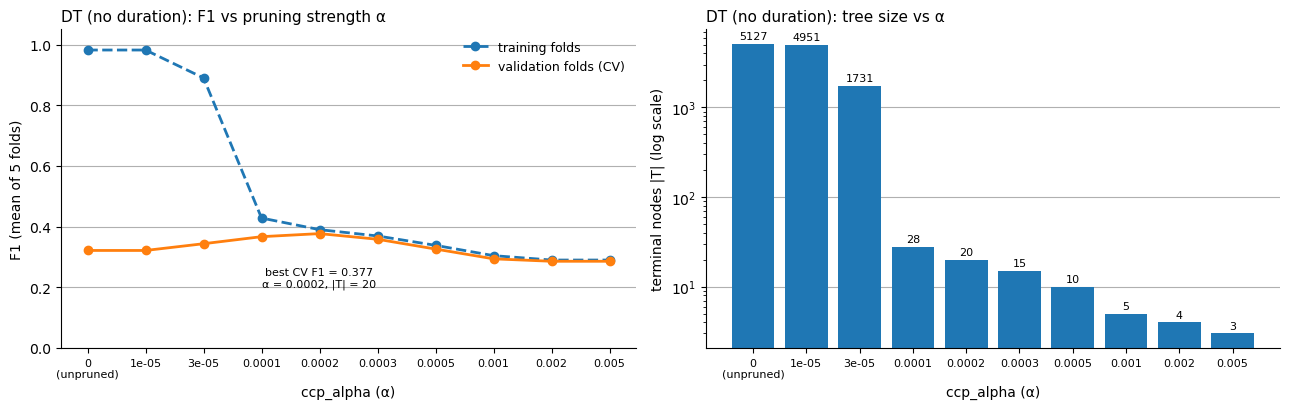

In [32]:
pruning_no_dur = pruning_curve(featurenoduration, "DT (no duration)")

Joint tuning of the key parameters with 5-fold stratified CV and refit

In [33]:
dt_no_duration = fit_model("DT (no duration)",
                           DecisionTreeClassifier(random_state=RANDOM_STATE),
                           DT_GRID,
                           X_train[featurenoduration])
describe_selected_tree("DT (no duration)")

[Loaded] DT (no duration)
Best parameters: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 50}
CV f1: 0.3894 ± 0.0144
Selected tree: criterion = gini, depth = 28, terminal nodes |T| = 1140

Top 5 of 360 settings by mean CV f1:


,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split,mean CV f1,std
0,0.0,gini,None,1,50,0.3894,0.0144
1,0.0,gini,None,1,200,0.3892,0.0140
2,0.0,gini,15,1,200,0.3886,0.0134
3,0.0,gini,10,20,200,0.3877,0.0148
4,0.0,gini,None,20,200,0.3877,0.0148


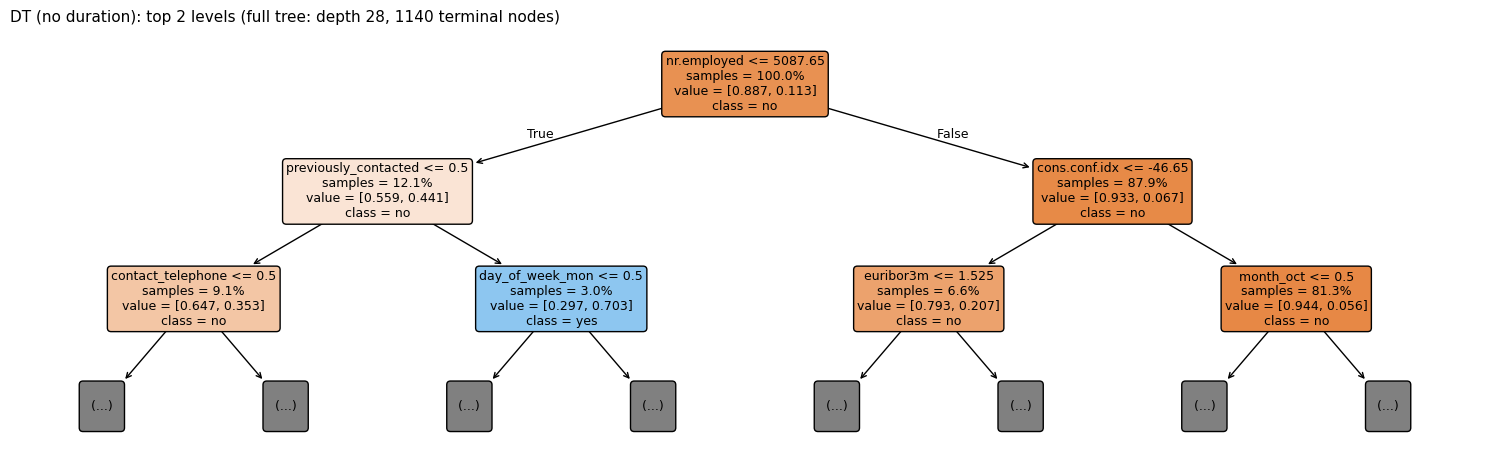

In [34]:
plot_top_of_tree("DT (no duration)")

### Model 3: Logistic Regression — with duration

[Loaded] LR (with duration)
Best parameters: {'C': 1}
CV f1: 0.5178 ± 0.0074


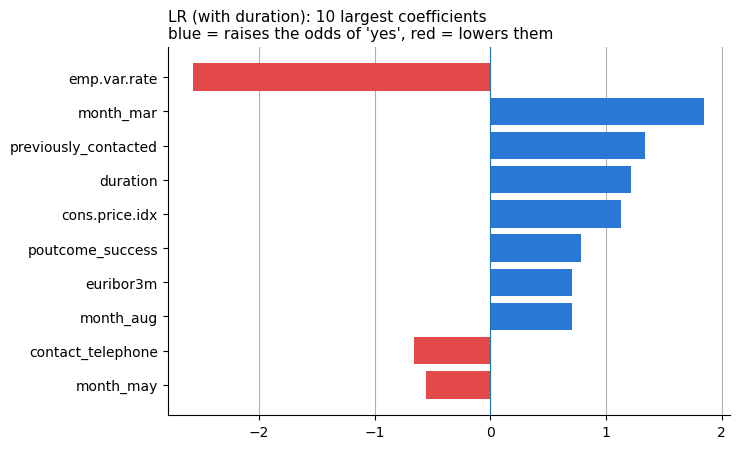

In [35]:
lr_with_duration = fit_model("LR (with duration)",
                             LogisticRegression(solver="lbfgs", max_iter=1000),
                             lr_grid,
                             X_train_scaled[featurewithduration])
plot_lr_coefficients("LR (with duration)")

### Model 4: Decision Tree with duration

,ccp_alpha,terminal nodes |T|,depth,train F1,CV F1,train accuracy,CV accuracy
0,0.00000,2437,27,1.0000,0.5198,1.0000,0.8891
1,0.00001,2437,27,1.0000,0.5198,1.0000,0.8891
2,0.00003,1739,27,0.9908,0.5252,0.9979,0.8917
3,0.00010,121,12,0.6911,0.5879,0.9339,0.9120
4,0.00020,29,8,0.6166,0.5963,0.9194,0.9155
5,0.00030,24,7,0.6044,0.5934,0.9176,0.9156
6,0.00050,17,6,0.6130,0.5993,0.9168,0.9141
7,0.00100,10,4,0.5864,0.5749,0.9142,0.9123
8,0.00200,7,3,0.5904,0.5864,0.9080,0.9073
9,0.00500,4,2,0.4906,0.4880,0.9030,0.9026


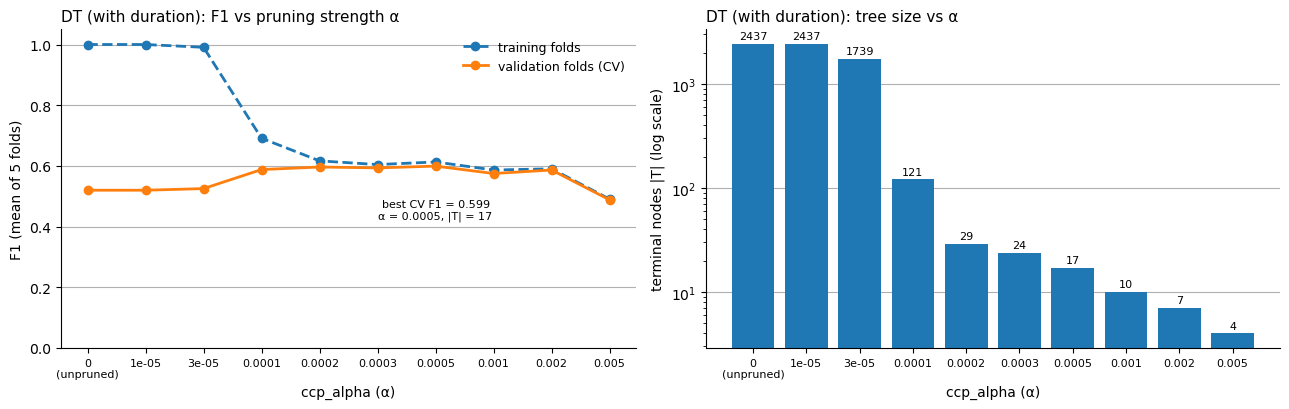

In [36]:
pruning_with_dur = pruning_curve(featurewithduration, "DT (with duration)")

Joint tuning of the key parameters with 5-fold and refit

In [37]:
dt_with_duration = fit_model("DT (with duration)",
                             DecisionTreeClassifier(random_state=RANDOM_STATE),
                             DT_GRID,
                             X_train[featurewithduration])
describe_selected_tree("DT (with duration)")

[Loaded] DT (with duration)
Best parameters: {'ccp_alpha': 0.0003, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
CV f1: 0.6003 ± 0.0099
Selected tree: criterion = entropy, depth = 10, terminal nodes |T| = 55

Top 5 of 360 settings by mean CV f1:


,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split,mean CV f1,std
0,0.0003,entropy,10,1,2,0.6003,0.0099
1,0.0003,entropy,None,1,2,0.6000,0.0096
2,0.0003,entropy,15,1,2,0.6000,0.0096
3,0.0003,entropy,None,20,2,0.5999,0.0102
4,0.0003,entropy,15,20,2,0.5999,0.0102


Top of the selected tree

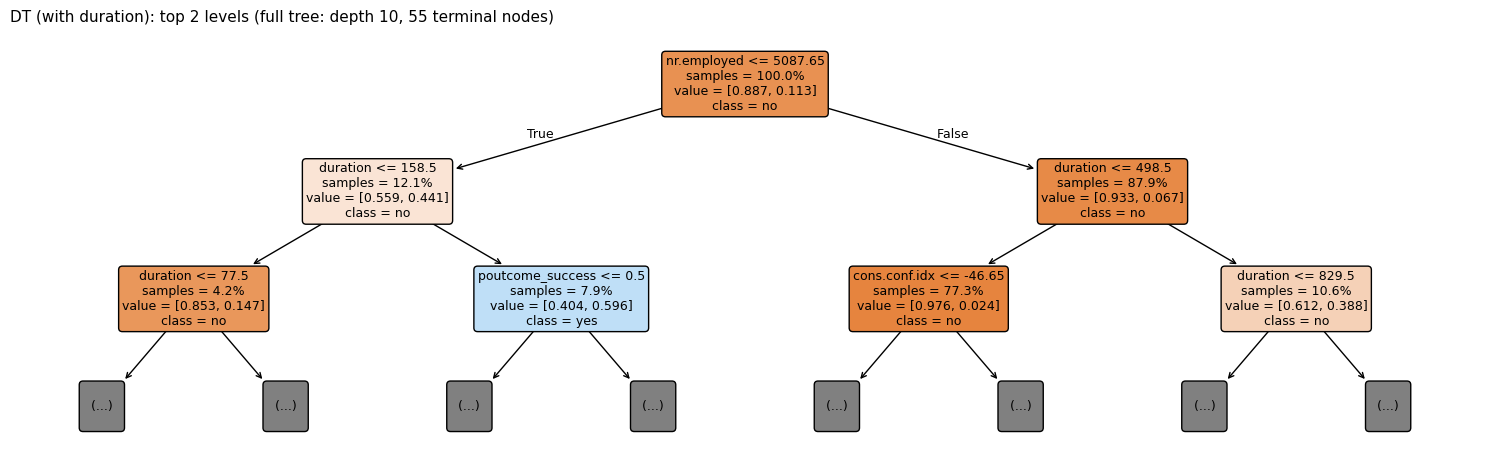

In [38]:
plot_top_of_tree("DT (with duration)")

important variables:

X_train: train feature	

y_train: train label	

X_test:	test feature	

y_test:	test label	

X_test：imput to model to let model predict

y_test：true reesult, used to compare with predicted result.

lr_no_duration: logistic model without duration

lr_with_duration: logistic model with duration 

dt_no_duration	: decision tree without duration

dt_with_duration: decision tree with duration.


In [39]:
# Save models
for name, grid in list(grids.items()):
    if name in MODEL_INPUTS:
        input_type, cols = MODEL_INPUTS[name]
        source = X_train_scaled if input_type == "scaled" else X_train
        save_grid(name, grid, source[cols])
        print("Saved:", name)

print("Saved outcome：", RUN_DIR)

Saved: LR (no duration)
Saved: DT (no duration)
Saved: LR (with duration)
Saved: DT (with duration)
Saved outcome： D:\Software\JupyterNotebooks\NTU\KM6312_GroupProject\bank-additional\LT\model_cache\383280d67dd0bae91812a8951e5c643f


## SVM + RF + GB (ZHUJINGYU)

### Model 5 SVM without duration

In [41]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

def make_svm(feature_cols):
    numeric_cols = [
        col for col in NUMERIC_COLS
        if col in feature_cols
    ]

    return Pipeline([
        ("preprocess", ColumnTransformer(
            transformers=[
                ("numeric", StandardScaler(), numeric_cols),
            ],
            remainder="passthrough",  # 保留 one-hot 和 binary 特征
        )),
        ("svc", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=False,
            cache_size=256,
            random_state=RANDOM_STATE,
        )),
    ])


svm_grid = {
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale"],
}

In [42]:
# Model 5: SVM without duration
svm_no_duration = fit_model(
    "SVM (no duration)",
    make_svm(featurenoduration),
    svm_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

[Loaded] SVM (no duration)
Best parameters: {'svc__C': 1, 'svc__gamma': 'scale'}
CV f1: 0.4665 ± 0.0116


### Model 6 SVM with duration

In [43]:
# Model 6: SVM with duration
svm_with_duration = fit_model(
    "SVM (with duration)",
    make_svm(featurewithduration),
    svm_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

[Loaded] SVM (with duration)
Best parameters: {'svc__C': 1, 'svc__gamma': 'scale'}
CV f1: 0.5773 ± 0.0080


In [44]:
def evaluate_svm(name, model, feature_cols):
    X_eval = X_test[feature_cols]

    y_pred = model.predict(X_eval)
    y_score = model.decision_function(X_eval)

    return {
        "model": name,
        "accuracy": metrics.accuracy_score(y_test, y_pred),
        "precision": metrics.precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": metrics.recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1": metrics.f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": metrics.roc_auc_score(y_test, y_score),
    }


svm_results = pd.DataFrame([
    evaluate_svm(
        "SVM (no duration)",
        svm_no_duration,
        featurenoduration,
    ),
    evaluate_svm(
        "SVM (with duration)",
        svm_with_duration,
        featurewithduration,
    ),
]).set_index("model")

display(svm_results.round(4))

svm_results.to_csv(RUN_DIR / "svm_test_results.csv")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
SVM (no duration),0.8482,0.3935,0.6412,0.4877,0.7848
SVM (with duration),0.8543,0.4324,0.9375,0.5918,0.9384


### Model 7 RF without duration

In [46]:
from sklearn.ensemble import RandomForestClassifier

def make_rf():
    return RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1,  # 外层 GridSearchCV 已并行，避免嵌套并行
    )


# 每个版本：4 组参数 × 5 folds，再 refit 最佳模型
rf_grid = {
    "max_depth": [15, None],
    "min_samples_leaf": [1, 5],
}

In [47]:
# Model 7: Random Forest without duration
rf_no_duration = fit_model(
    "RF (no duration)",
    make_rf(),
    rf_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

[Trained & saved] RF (no duration)
Best parameters: {'max_depth': None, 'min_samples_leaf': 5}
CV f1: 0.4963 ± 0.0123


### Model 8 RF with duration

In [48]:
# Model 8: Random Forest with duration
rf_with_duration = fit_model(
    "RF (with duration)",
    make_rf(),
    rf_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

[Trained & saved] RF (with duration)
Best parameters: {'max_depth': 15, 'min_samples_leaf': 1}
CV f1: 0.6333 ± 0.0041


### Model 9 GB without duration

In [45]:
from sklearn.ensemble import GradientBoostingClassifier

# Use one-hot encoded data without standardization
def make_gb():
    return GradientBoostingClassifier(
        max_depth=2,
        random_state=RANDOM_STATE,
    )

# Per version: 4 configurations × 5 CV folds, followed by best-model refitting
gb_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
}

In [46]:

# Model: Gradient Boosting without call duration
gb_no_duration = fit_model(
    "GB (no duration)",
    make_gb(),
    gb_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] GB (no duration)
Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
CV f1: 0.3487 ± 0.0097


### Model 10 GB with duration

In [49]:
# Model: Gradient Boosting with call duration
gb_with_duration = fit_model(
    "GB (with duration)",
    make_gb(),
    gb_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] GB (with duration)
Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
CV f1: 0.5689 ± 0.0072


In [50]:
# Inspect hyperparameter search results for both versions
for name in ["GB (no duration)", "GB (with duration)"]:
    search = grids[name]
    cv_results = pd.DataFrame(search.cv_results_)

    print(f"\n{name}")
    display(
        cv_results[[
            "param_n_estimators",
            "param_learning_rate",
            "mean_test_accuracy",
            "mean_test_precision",
            "mean_test_recall",
            "mean_test_f1",
            "mean_test_roc_auc",
            "std_test_f1",
        ]]
        .sort_values(
            by=f"mean_test_{REFIT_METRIC}",
            ascending=False,
        )
        .round(4)
    )

    print("Best parameters:", search.best_params_)
    print(f"Best CV {REFIT_METRIC}: {search.best_score_:.4f}")


GB (no duration)


,param_n_estimators,param_learning_rate,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc,std_test_f1
3,200,0.10,0.9008,0.6691,0.2358,0.3487,0.7956,0.0097
2,100,0.10,0.9005,0.6846,0.2169,0.3293,0.7936,0.0063
1,200,0.05,0.9005,0.6880,0.2142,0.3266,0.7934,0.0062
0,100,0.05,0.8998,0.7007,0.1943,0.3041,0.7910,0.0052


Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
Best CV f1: 0.3487

GB (with duration)


,param_n_estimators,param_learning_rate,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc,std_test_f1
3,200,0.10,0.9143,0.6567,0.5020,0.5689,0.9439,0.0072
2,100,0.10,0.9135,0.6591,0.4813,0.5562,0.9417,0.0046
1,200,0.05,0.9133,0.6588,0.4788,0.5544,0.9418,0.0058
0,100,0.05,0.9114,0.6645,0.4330,0.5241,0.9391,0.0086


Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
Best CV f1: 0.5689


# 加了个简单的evaluation